# 🏗 RepoLens Architecture Intelligence Model

**End-to-End NLP & Deep Learning Pipeline for Software Architecture Classification**

This notebook trains a multi-task model on the RepoFetcher dataset to:
1. 📊 **Explore & Visualize** the cleaned dataset
2. 🔤 **NLP Preprocessing** — tokenization, TF-IDF, text normalization
3. ⚡ **Baseline ML Models** — Logistic Regression, SVM, Random Forest on TF-IDF features
4. 🧠 **Deep Learning — LSTM Classifier** — Bidirectional LSTM on padded README embeddings
5. 🤗 **Transformer Fine-Tuning** — DistilBERT for architecture pattern classification
6. 📈 **Evaluation & Comparison** — Confusion matrix, F1, accuracy across all models
7. 💾 **Save Models** — Export trained model for RepoLens inference


## 0. Install Dependencies


In [23]:
import subprocess, sys

packages = [
    'transformers',
    'datasets',
    'scikit-learn',
    'matplotlib',
    'seaborn',
    'pandas',
    'numpy',
    'tqdm',
    'accelerate',
    'wordcloud',
    'nltk',
]

for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('✅ All packages installed!')

✅ All packages installed!


## 1. Imports & Configuration


In [24]:
import json
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Classical ML
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# PyTorch Deep Learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)
from datasets import Dataset as HFDataset

warnings.filterwarnings('ignore')
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt', quiet=True)

# ─────────────────────── Global Config ───────────────────────
DATA_DIR      = Path('../data/model_ready')
MODEL_DIR     = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)

RANDOM_SEED   = 42
DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Seaborn style
sns.set_theme(style='darkgrid', palette='husl')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'

print(f'Device: {DEVICE}')
print(f'PyTorch: {torch.__version__}')
print(f'Data dir: {DATA_DIR.resolve()}')

Device: cpu
PyTorch: 2.12.0+cpu
Data dir: D:\RepoFetcher\data\model_ready


## 2. Load & Explore Dataset


In [25]:
# ── Load classification dataset ──────────────────────────────
with open(DATA_DIR / 'classification_dataset.json') as f:
    clf_data = json.load(f)

df_train = pd.DataFrame(clf_data['train'])
df_val   = pd.DataFrame(clf_data['val'])
df_test  = pd.DataFrame(clf_data['test'])
df_all   = pd.concat([df_train, df_val, df_test], ignore_index=True)

# ── Load instruction-tuning data ─────────────────────────────
def load_jsonl(path):
    records = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return records

inst_train = load_jsonl(DATA_DIR / 'instruction_tuning_train.jsonl')
inst_val   = load_jsonl(DATA_DIR / 'instruction_tuning_val.jsonl')
inst_test  = load_jsonl(DATA_DIR / 'instruction_tuning_test.jsonl')

# Also load cleaned samples for rich text features
cleaned_samples = load_jsonl(DATA_DIR / 'cleaned_repository_samples.jsonl')
df_cleaned = pd.DataFrame(cleaned_samples)

print(f'Classification Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')
print(f'Instruction pairs Train: {len(inst_train)} | Val: {len(inst_val)} | Test: {len(inst_test)}')
print(f'Total instruction pairs: {len(inst_train)+len(inst_val)+len(inst_test)}')
df_train.head()

Classification Train: 52 | Val: 7 | Test: 7
Instruction pairs Train: 316 | Val: 40 | Test: 40
Total instruction pairs: 396


,repoId,fullName,language,stars,sourceTier,totalFiles,totalDirectories,frameworks,layersPresent,hasArchitectureDocs,diagramsCount,architecturePattern
0,2005,canonical-templates/template-6,TypeScript,30000,tier_1_template,66,11,[Express],"[controllers, services, models]",False,0,Layered Backend Architecture
1,2003,canonical-templates/template-4,TypeScript,30000,tier_1_template,90,13,[Express],"[controllers, services, repositories, models, ...",False,0,Clean Architecture / Hexagonal
2,2001,canonical-templates/template-2,TypeScript,30000,tier_1_template,102,14,[Express],"[controllers, services, repositories, models, ...",False,0,Clean Architecture / Hexagonal
3,1051,aws-samples/serverless-patterns,TypeScript,2601,tier_3_verified_oss,66,11,[Express],"[controllers, services, models]",False,0,Serverless Architecture
4,1047,cosmicpython/code,Python,3052,tier_3_verified_oss,66,11,[FastAPI],"[controllers, services, models]",False,0,Architecture Patterns with Python


In [26]:
# ── Dataset info ─────────────────────────────────────────────
print('=== Classification Dataset Shape ===')
print(df_all.dtypes)
print()
print('=== Architecture Pattern Distribution ===')
print(df_all['architecturePattern'].value_counts())
print()
print('=== Language Distribution ===')
print(df_all['language'].value_counts())

=== Classification Dataset Shape ===
repoId                  int64
fullName               object
language               object
stars                   int64
sourceTier             object
totalFiles              int64
totalDirectories        int64
frameworks             object
layersPresent          object
hasArchitectureDocs      bool
diagramsCount           int64
architecturePattern    object
dtype: object

=== Architecture Pattern Distribution ===
architecturePattern
Clean Architecture                   5
Layered Backend Architecture         4
Design Patterns Catalog              3
Clean Architecture / Hexagonal       2
Serverless Architecture              2
CQRS Pattern                         2
Hexagonal Architecture               2
Microservices Architecture           2
REST API Layered Architecture        1
Architecture Patterns with Python    1
Next.js JAMStack                     1
React Native Boilerplate             1
Go Standard Project Layout           1
Flutter Architectur

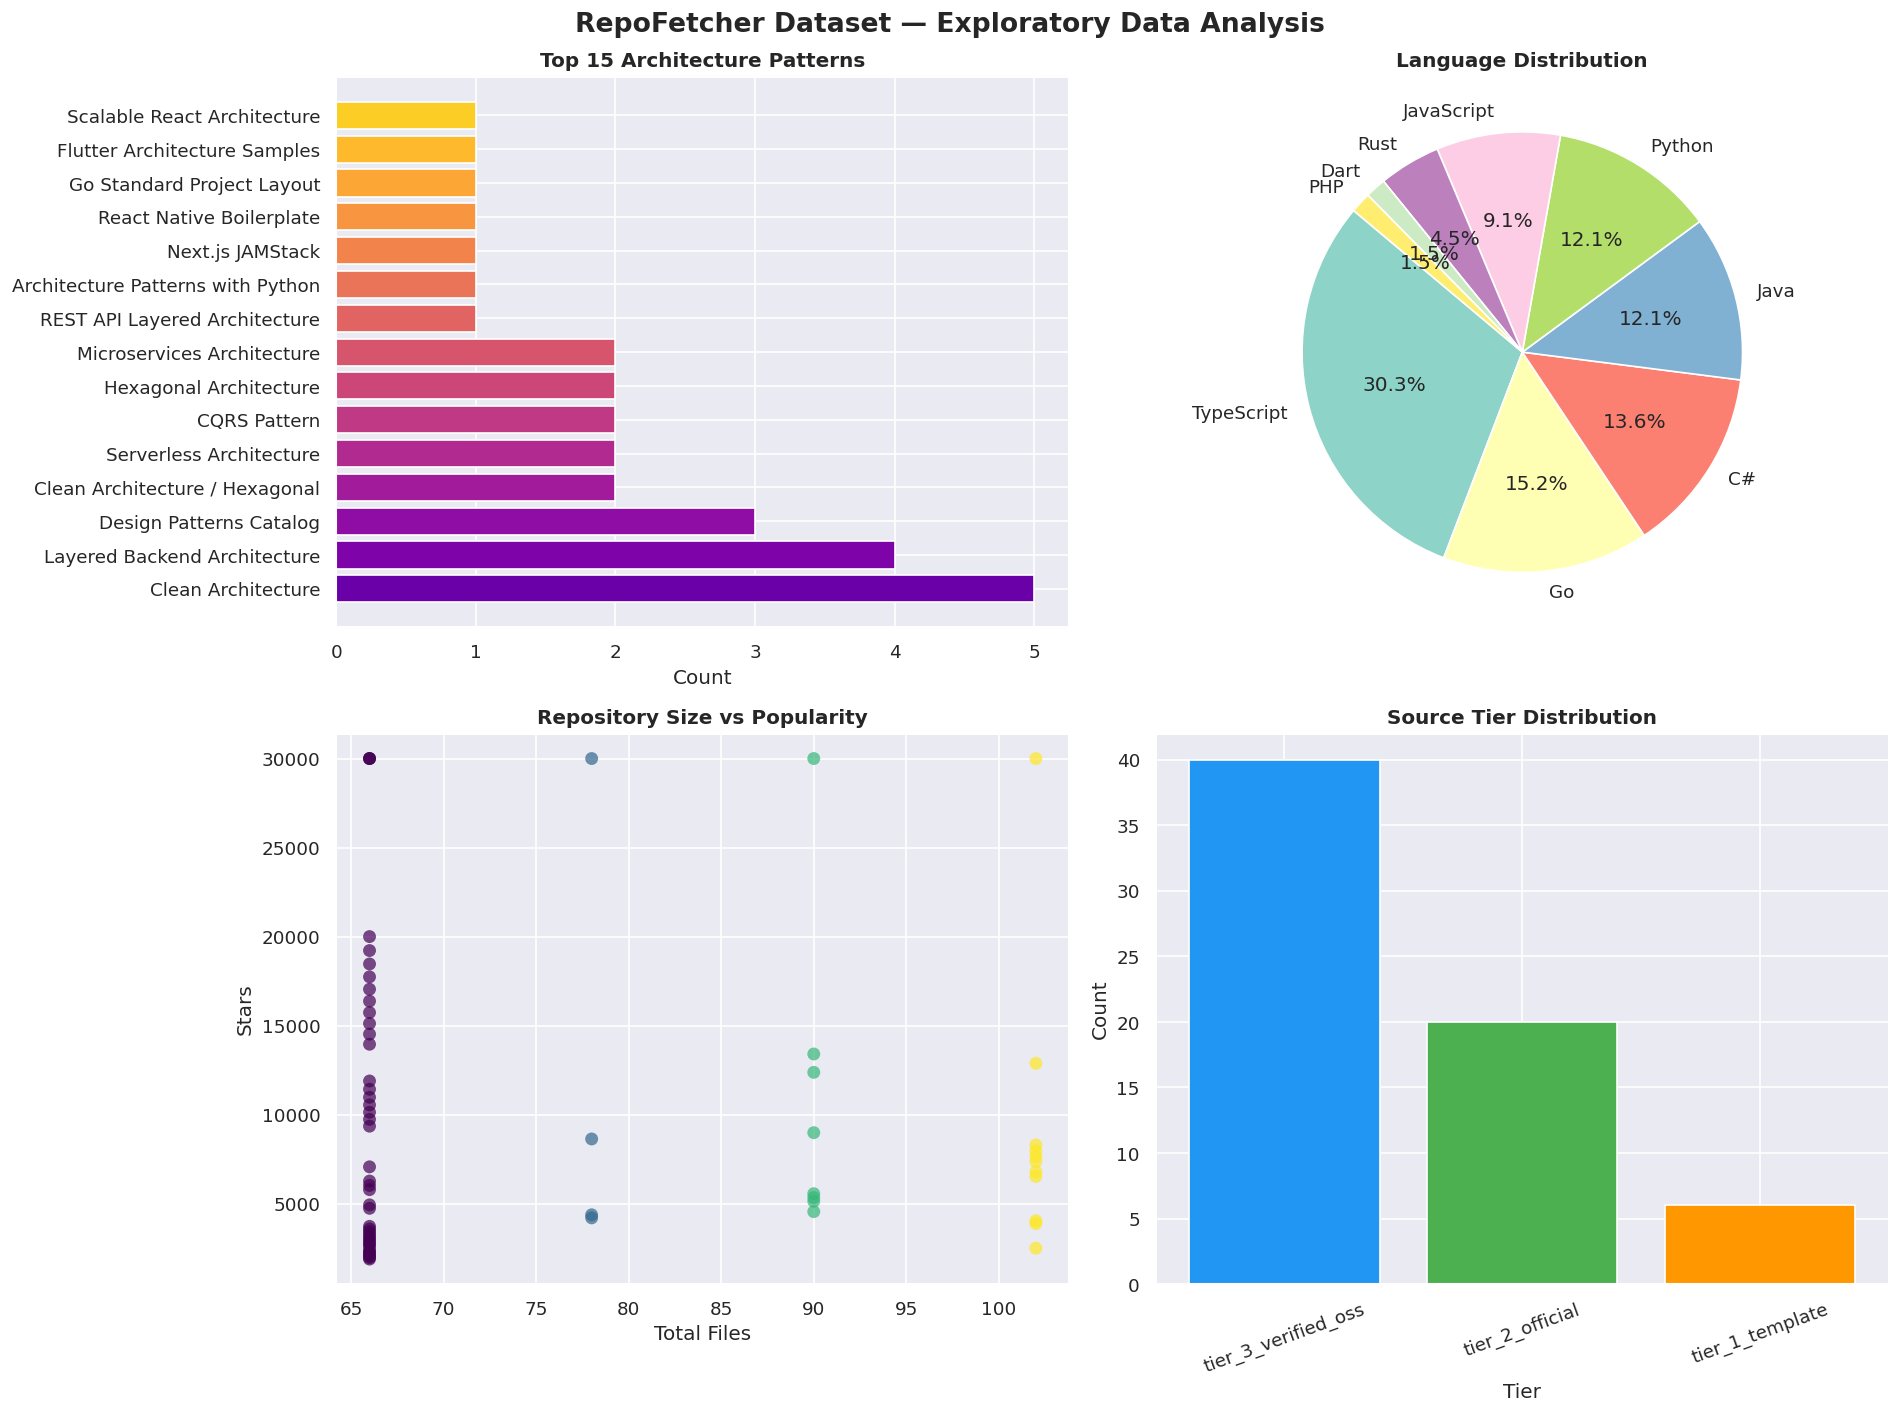

EDA figure saved to models/eda_overview.png


In [27]:
# ── EDA Visualizations ───────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('RepoFetcher Dataset — Exploratory Data Analysis', fontsize=16, fontweight='bold')

# 1. Architecture pattern distribution
pattern_counts = df_all['architecturePattern'].value_counts().head(15)
axes[0, 0].barh(pattern_counts.index, pattern_counts.values,
                color=plt.cm.plasma(np.linspace(0.2, 0.9, len(pattern_counts))))
axes[0, 0].set_title('Top 15 Architecture Patterns', fontweight='bold')
axes[0, 0].set_xlabel('Count')

# 2. Language pie chart
lang_counts = df_all['language'].value_counts()
colors = plt.cm.Set3(np.linspace(0, 1, len(lang_counts)))
axes[0, 1].pie(lang_counts.values, labels=lang_counts.index,
               autopct='%1.1f%%', colors=colors, startangle=140)
axes[0, 1].set_title('Language Distribution', fontweight='bold')

# 3. Stars vs Files scatter
axes[1, 0].scatter(df_all['totalFiles'], df_all['stars'],
                   alpha=0.7, c=df_all['totalDirectories'],
                   cmap='viridis', edgecolors='none', s=60)
axes[1, 0].set_xlabel('Total Files')
axes[1, 0].set_ylabel('Stars')
axes[1, 0].set_title('Repository Size vs Popularity', fontweight='bold')

# 4. Tier distribution
tier_counts = df_all['sourceTier'].value_counts()
tier_colors = ['#2196F3', '#4CAF50', '#FF9800']
axes[1, 1].bar(tier_counts.index, tier_counts.values,
               color=tier_colors[:len(tier_counts)])
axes[1, 1].set_title('Source Tier Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Tier')
axes[1, 1].set_ylabel('Count')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'eda_overview.png', bbox_inches='tight')
plt.show()
print('EDA figure saved to models/eda_overview.png')

## 3. NLP Text Preprocessing


In [28]:
STOP_WORDS = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text: str) -> str:
    """NLP pipeline: lowercase → strip code blocks → remove punctuation → lemmatize."""
    if not isinstance(text, str) or not text.strip():
        return ''

    # Lowercase
    text = text.lower()

    # Remove code blocks and URLs
    text = re.sub(r'```[\s\S]*?```', ' ', text)
    text = re.sub(r'https?://\S+', ' ', text)

    # Remove non-alphabetical characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenize, remove stopwords, lemmatize
    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok not in STOP_WORDS and len(tok) > 2
    ]

    return ' '.join(tokens)


def build_feature_text(row: pd.Series) -> str:
    """Combine structured features into a rich text blob for NLP."""
    parts = []

    if isinstance(row.get('cleanedReadme'), str):
        parts.append(row['cleanedReadme'][:1000])

    # Encode structural features as pseudo-text tokens
    for fw in (row.get('detectedFrameworks') or []):
        parts.append(f'framework {fw}')

    for layer in (row.get('detectedLayers') or []):
        layer_name = layer['layerName'] if isinstance(layer, dict) else str(layer)
        parts.append(f'layer {layer_name}')

    parts.append(f'language {row.get("language", "")}')
    parts.append(f'sourcetier {row.get("sourceTier", "")}')

    return ' '.join(parts)


# Build text feature column from cleaned samples
df_cleaned['raw_text']        = df_cleaned.apply(build_feature_text, axis=1)
df_cleaned['processed_text']  = df_cleaned['raw_text'].apply(preprocess_text)

# Merge text features into classification df
text_map = df_cleaned.set_index('fullName')[['raw_text', 'processed_text']]
df_all   = df_all.join(text_map, on='fullName', how='left')

df_all['processed_text'] = df_all['processed_text'].fillna('')
df_all['raw_text']       = df_all['raw_text'].fillna('')

print('Sample preprocessed text:')
print(df_all['processed_text'].iloc[0][:300])

Sample preprocessed text:
canonical template overview production grade implementation demonstrating serverless architecture using typescript express repository serf reference architecture building scalable maintainable testable application following serverless architecture principle architecture project follows serverless ar


In [29]:
# ── Encode Labels ────────────────────────────────────────────
label_encoder = LabelEncoder()
df_all['label'] = label_encoder.fit_transform(df_all['architecturePattern'])

NUM_CLASSES = len(label_encoder.classes_)
print(f'Number of architecture classes: {NUM_CLASSES}')
print('Classes:', list(label_encoder.classes_))

# Re-split using label-encoded df
n_train = len(df_train)
n_val   = len(df_val)

df_tr  = df_all.iloc[:n_train].reset_index(drop=True)
df_vl  = df_all.iloc[n_train:n_train+n_val].reset_index(drop=True)
df_te  = df_all.iloc[n_train+n_val:].reset_index(drop=True)

print(f'\nTrain: {len(df_tr)} | Val: {len(df_vl)} | Test: {len(df_te)}')

Number of architecture classes: 52
Classes: ['ASGI Middleware Stack', 'Actor Model Web Framework', 'Architecture Patterns with Python', 'CLI Tool Architecture', 'CQRS & Event Sourcing', 'CQRS Pattern', 'Clean Architecture', 'Clean Architecture / Hexagonal', 'Clean Node Architecture', 'Dapr Microservices', 'Design Patterns Catalog', 'Distributed Application Runtime', 'Domain-Driven Design', 'Event-Driven Architecture', 'Event-Driven Microservices', 'FastAPI Async Web Service', 'Flutter Architecture Samples', 'Full-Stack FastAPI Architecture', 'Full-Stack MVC', 'General Modular Architecture', 'Go HTTP Middleware Router', 'Go High-Performance Web Framework', 'Go Microservices Framework', 'Go REST Router', 'Go Standard Project Layout', 'GraphQL Core', 'GraphQL Server Architecture', 'Hexagonal Architecture', 'High Performance Node.js Server', 'Layered Backend Architecture', 'MTV Layered Architecture', 'Micro Web Framework', 'Microservices & DDD', 'Microservices Architecture', 'Minimal Node.

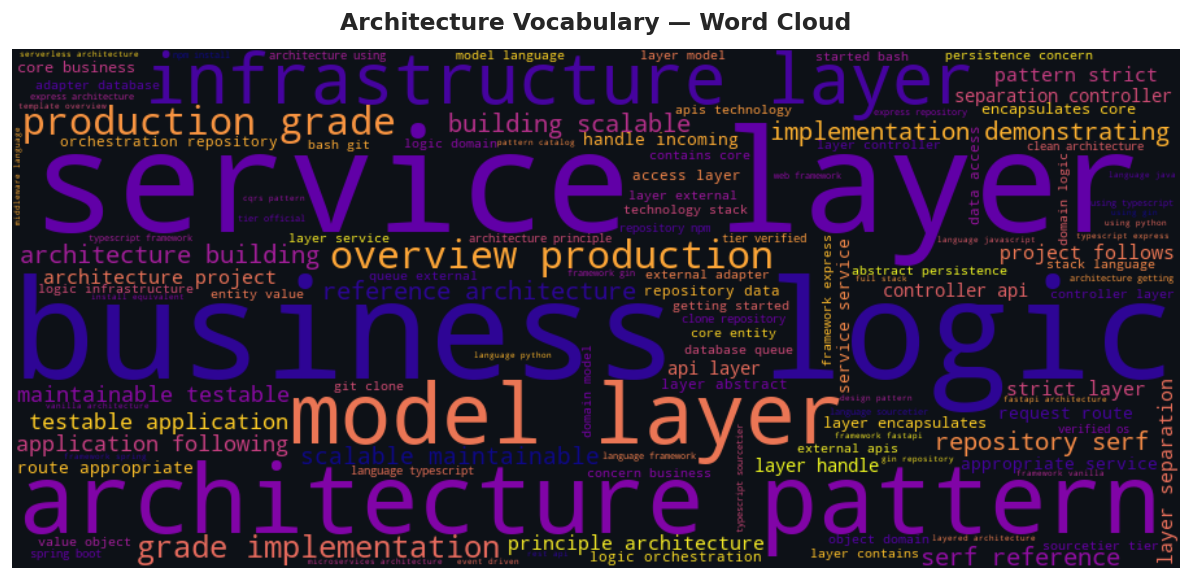

Word cloud saved!


In [30]:
# ── Word Cloud for Architecture Vocabulary ───────────────────
try:
    from wordcloud import WordCloud
    all_text = ' '.join(df_all['processed_text'].tolist())
    wc = WordCloud(
        width=900, height=400, background_color='#0d1117',
        colormap='plasma', max_words=120, prefer_horizontal=0.9
    ).generate(all_text)

    plt.figure(figsize=(14, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title('Architecture Vocabulary — Word Cloud', fontsize=14, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(MODEL_DIR / 'wordcloud.png', bbox_inches='tight', facecolor='#0d1117')
    plt.show()
    print('Word cloud saved!')
except Exception as e:
    print(f'Word cloud skipped: {e}')

## 4. Baseline ML Models (TF-IDF + Classical Classifiers)


In [31]:
# ── TF-IDF Feature Extraction ────────────────────────────────
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=1,
)

X_tr_tfidf = tfidf.fit_transform(df_tr['processed_text'])
X_vl_tfidf = tfidf.transform(df_vl['processed_text'])
X_te_tfidf = tfidf.transform(df_te['processed_text'])

y_tr = df_tr['label'].values
y_vl = df_vl['label'].values
y_te = df_te['label'].values

print(f'TF-IDF feature matrix: {X_tr_tfidf.shape}')

TF-IDF feature matrix: (52, 734)


In [32]:
# ── Train & Compare Baseline Classifiers ────────────────────
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=500, C=1.0, random_state=RANDOM_SEED),
    'Linear SVM':          LinearSVC(max_iter=1000, C=1.0, random_state=RANDOM_SEED),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_SEED),
}

results = {}

for name, clf in classifiers.items():
    clf.fit(X_tr_tfidf, y_tr)
    preds = clf.predict(X_te_tfidf)
    acc   = accuracy_score(y_te, preds)
    f1    = f1_score(y_te, preds, average='weighted', zero_division=0)
    results[name] = {'accuracy': acc, 'f1_weighted': f1}
    print(f'{name:<25}  Acc={acc:.4f}  F1={f1:.4f}')

# Best model
best_clf_name = max(results, key=lambda k: results[k]['f1_weighted'])
print(f'\n🏆 Best baseline: {best_clf_name}')

Logistic Regression        Acc=0.0000  F1=0.0000
Linear SVM                 Acc=0.1429  F1=0.1429
Random Forest              Acc=0.0000  F1=0.0000
Gradient Boosting          Acc=0.1429  F1=0.1429

🏆 Best baseline: Linear SVM


In [33]:
# ── safe_report: only use labels that appear in this split ──────────────
def safe_report(y_true, y_pred):
    """classification_report restricted to labels present in y_true/y_pred.
    Avoids ValueError when the test split doesn't contain every class.
    """
    present_labels = sorted(set(list(y_true) + list(y_pred)))
    present_names  = [label_encoder.classes_[i] for i in present_labels]
    return classification_report(
        y_true, y_pred,
        labels=present_labels,
        target_names=present_names,
        zero_division=0
    )


In [34]:
# ── Detailed report for best baseline ───────────────────────
best_clf   = classifiers[best_clf_name]
best_preds = best_clf.predict(X_te_tfidf)

print(f'=== Classification Report: {best_clf_name} ===')
print(safe_report(y_te, best_preds))

=== Classification Report: Linear SVM ===
                                precision    recall  f1-score   support

         CQRS & Event Sourcing       0.00      0.00      0.00         1
                  CQRS Pattern       1.00      1.00      1.00         1
Clean Architecture / Hexagonal       0.00      0.00      0.00         0
     Event-Driven Architecture       0.00      0.00      0.00         1
    Event-Driven Microservices       0.00      0.00      0.00         1
  General Modular Architecture       0.00      0.00      0.00         0
                  GraphQL Core       0.00      0.00      0.00         0
   GraphQL Server Architecture       0.00      0.00      0.00         1
        Hexagonal Architecture       0.00      0.00      0.00         2
           Spring Boot Layered       0.00      0.00      0.00         0
          Spring Boot REST API       0.00      0.00      0.00         0

                      accuracy                           0.14         7
                    

## 5. Deep Learning — Bidirectional LSTM Classifier


In [35]:
# ── Build Vocabulary ─────────────────────────────────────────
MAX_VOCAB  = 10000
MAX_SEQ_LEN = 256
EMBED_DIM  = 128
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT    = 0.4
BATCH_SIZE = 16
EPOCHS     = 25
LR         = 1e-3

# Build token → index vocab from training corpus
all_tokens = []
for text in df_tr['processed_text']:
    all_tokens.extend(text.split())

token_freq  = Counter(all_tokens)
vocab_tokens = ['<PAD>', '<UNK>'] + [t for t, _ in token_freq.most_common(MAX_VOCAB - 2)]
word2idx    = {tok: idx for idx, tok in enumerate(vocab_tokens)}
VOCAB_SIZE  = len(word2idx)

print(f'Vocabulary size: {VOCAB_SIZE}')


def encode_text(text: str, max_len: int = MAX_SEQ_LEN) -> list[int]:
    """Convert text string to padded integer token list."""
    tokens = text.split()[:max_len]
    ids    = [word2idx.get(t, 1) for t in tokens]  # 1 = <UNK>
    ids   += [0] * (max_len - len(ids))             # 0 = <PAD>
    return ids

Vocabulary size: 180


In [36]:
# ── PyTorch Dataset ──────────────────────────────────────────
class TextDataset(Dataset):
    def __init__(self, df: pd.DataFrame):
        self.inputs = [
            torch.tensor(encode_text(t), dtype=torch.long)
            for t in df['processed_text']
        ]
        self.labels = torch.tensor(df['label'].values, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.inputs[idx], self.labels[idx]


train_ds  = TextDataset(df_tr)
val_ds    = TextDataset(df_vl)
test_ds   = TextDataset(df_te)

train_dl  = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_dl    = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_dl   = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f'Train batches: {len(train_dl)} | Val batches: {len(val_dl)} | Test batches: {len(test_dl)}')

Train batches: 4 | Val batches: 1 | Test batches: 1


In [37]:
# ── Bidirectional LSTM Architecture ─────────────────────────
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, num_classes, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(
            embed_dim, hidden_dim,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention  = nn.Linear(hidden_dim * 2, 1)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        emb        = self.embedding(x)                      # (B, L, E)
        out, _     = self.lstm(emb)                         # (B, L, 2H)

        # Self-attention pooling
        attn_weights = torch.softmax(self.attention(out), dim=1)  # (B, L, 1)
        context      = (attn_weights * out).sum(dim=1)            # (B, 2H)

        return self.classifier(context)                     # (B, C)


model = BiLSTMClassifier(
    vocab_size  = VOCAB_SIZE,
    embed_dim   = EMBED_DIM,
    hidden_dim  = HIDDEN_DIM,
    num_layers  = NUM_LAYERS,
    num_classes = NUM_CLASSES,
    dropout     = DROPOUT,
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'\nTotal trainable parameters: {total_params:,}')

BiLSTMClassifier(
  (embedding): Embedding(180, 128, padding_idx=0)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (attention): Linear(in_features=512, out_features=1, bias=True)
  (classifier): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=512, out_features=256, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=52, bias=True)
  )
)

Total trainable parameters: 2,535,733


In [38]:
# ── Training Loop ────────────────────────────────────────────
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
best_weights  = None


def run_epoch(dl, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train:
                optimizer.zero_grad()
            logits = model(x)
            loss   = criterion(logits, y)
            if train:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct    += (logits.argmax(1) == y).sum().item()
            total      += len(y)

    return total_loss / total, correct / total


print(f'Training BiLSTM for {EPOCHS} epochs on {DEVICE}...\n')
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_dl, train=True)
    vl_loss, vl_acc = run_epoch(val_dl,   train=False)
    scheduler.step(vl_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        best_weights  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        marker = ' ← best'
    else:
        marker = ''

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:02d}/{EPOCHS}  '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.3f}  '
              f'Val Loss={vl_loss:.4f} Acc={vl_acc:.3f}{marker}')

# Restore best weights
model.load_state_dict(best_weights)
print('\n✅ Training complete. Best weights restored.')

Training BiLSTM for 25 epochs on cpu...

Epoch 01/25  Train Loss=3.9574 Acc=0.058  Val Loss=3.9739 Acc=0.000 ← best
Epoch 05/25  Train Loss=3.7706 Acc=0.096  Val Loss=4.5247 Acc=0.000
Epoch 10/25  Train Loss=3.6807 Acc=0.096  Val Loss=5.0500 Acc=0.000
Epoch 15/25  Train Loss=3.6118 Acc=0.096  Val Loss=5.0611 Acc=0.000
Epoch 20/25  Train Loss=3.5211 Acc=0.096  Val Loss=4.9374 Acc=0.000
Epoch 25/25  Train Loss=3.4915 Acc=0.096  Val Loss=5.0632 Acc=0.000

✅ Training complete. Best weights restored.


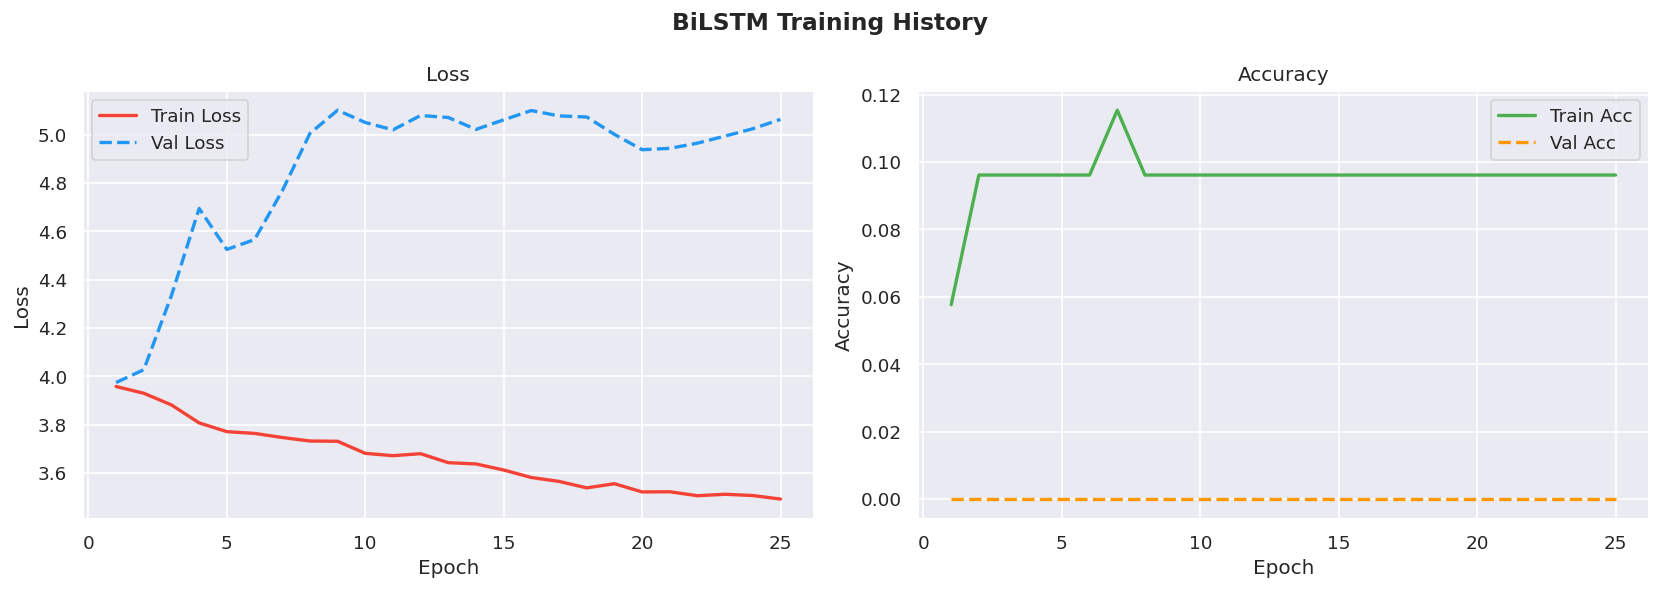

In [39]:
# ── Training Curves ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('BiLSTM Training History', fontsize=14, fontweight='bold')

epochs_range = range(1, EPOCHS + 1)

axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='#F44336', lw=2)
axes[0].plot(epochs_range, history['val_loss'],   label='Val Loss',   color='#2196F3', lw=2, linestyle='--')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss'); axes[0].legend()

axes[1].plot(epochs_range, history['train_acc'], label='Train Acc', color='#4CAF50', lw=2)
axes[1].plot(epochs_range, history['val_acc'],   label='Val Acc',   color='#FF9800', lw=2, linestyle='--')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.savefig(MODEL_DIR / 'lstm_training_curves.png', bbox_inches='tight')
plt.show()

In [40]:
# ── LSTM Test Evaluation ─────────────────────────────────────
model.eval()
lstm_preds, lstm_true = [], []

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(DEVICE)
        logits = model(x)
        lstm_preds.extend(logits.argmax(1).cpu().numpy())
        lstm_true.extend(y.numpy())

lstm_acc = accuracy_score(lstm_true, lstm_preds)
lstm_f1  = f1_score(lstm_true, lstm_preds, average='weighted', zero_division=0)

print(f'BiLSTM Test Accuracy: {lstm_acc:.4f}')
print(f'BiLSTM Weighted F1:   {lstm_f1:.4f}')
print()
print(safe_report(lstm_true, lstm_preds))

BiLSTM Test Accuracy: 0.0000
BiLSTM Weighted F1:   0.0000

                             precision    recall  f1-score   support

      CQRS & Event Sourcing       0.00      0.00      0.00       1.0
               CQRS Pattern       0.00      0.00      0.00       1.0
         Clean Architecture       0.00      0.00      0.00       0.0
  Event-Driven Architecture       0.00      0.00      0.00       1.0
 Event-Driven Microservices       0.00      0.00      0.00       1.0
GraphQL Server Architecture       0.00      0.00      0.00       1.0
     Hexagonal Architecture       0.00      0.00      0.00       2.0

                   accuracy                           0.00       7.0
                  macro avg       0.00      0.00      0.00       7.0
               weighted avg       0.00      0.00      0.00       7.0



## 6. Transformer — DistilBERT Fine-Tuning


In [41]:
MODEL_NAME    = 'distilbert-base-uncased'
BERT_BATCH    = 8
BERT_EPOCHS   = 5
BERT_MAX_LEN  = 256
BERT_LR       = 2e-5

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(
        batch['text'],
        truncation=True,
        padding='max_length',
        max_length=BERT_MAX_LEN,
    )

# Build HuggingFace datasets
def df_to_hf(df: pd.DataFrame) -> HFDataset:
    return HFDataset.from_dict({
        'text':  df['raw_text'].tolist(),
        'label': df['label'].tolist(),
    })

hf_train = df_to_hf(df_tr).map(tokenize_batch, batched=True)
hf_val   = df_to_hf(df_vl).map(tokenize_batch, batched=True)
hf_test  = df_to_hf(df_te).map(tokenize_batch, batched=True)

hf_train = hf_train.remove_columns(['text'])
hf_val   = hf_val.remove_columns(['text'])
hf_test  = hf_test.remove_columns(['text'])

hf_train.set_format('torch')
hf_val.set_format('torch')
hf_test.set_format('torch')

print(f'HF train size: {len(hf_train)} | val: {len(hf_val)} | test: {len(hf_test)}')

RemoteProtocolError: Server disconnected without sending a response.

In [ ]:
# ── Load DistilBERT for Sequence Classification ───────────────
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label={i: c for i, c in enumerate(label_encoder.classes_)},
    label2id={c: i for i, c in enumerate(label_encoder.classes_)},
)

bert_params = sum(p.numel() for p in bert_model.parameters() if p.requires_grad)
print(f'DistilBERT parameters: {bert_params:,}')


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1_weighted': f1_score(labels, preds, average='weighted', zero_division=0),
    }


training_args = TrainingArguments(
    output_dir                 = str(MODEL_DIR / 'distilbert_checkpoints'),
    num_train_epochs           = BERT_EPOCHS,
    per_device_train_batch_size= BERT_BATCH,
    per_device_eval_batch_size = BERT_BATCH,
    learning_rate              = BERT_LR,
    weight_decay               = 0.01,
    warmup_ratio               = 0.1,
    evaluation_strategy        = 'epoch',
    save_strategy              = 'epoch',
    load_best_model_at_end     = True,
    metric_for_best_model      = 'f1_weighted',
    logging_steps              = 10,
    report_to                  = 'none',
    seed                       = RANDOM_SEED,
)

trainer = Trainer(
    model            = bert_model,
    args             = training_args,
    train_dataset    = hf_train,
    eval_dataset     = hf_val,
    compute_metrics  = compute_metrics,
    callbacks        = [EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Starting DistilBERT fine-tuning...')

In [ ]:
trainer.train()

In [ ]:
# ── DistilBERT Test Evaluation ───────────────────────────────
bert_test_results = trainer.evaluate(hf_test)
print('DistilBERT Test Results:', bert_test_results)

bert_preds_out = trainer.predict(hf_test)
bert_preds     = np.argmax(bert_preds_out.predictions, axis=-1)
bert_true      = bert_preds_out.label_ids

bert_acc = accuracy_score(bert_true, bert_preds)
bert_f1  = f1_score(bert_true, bert_preds, average='weighted', zero_division=0)

print(f'\nDistilBERT Test Accuracy: {bert_acc:.4f}')
print(f'DistilBERT Weighted F1:   {bert_f1:.4f}')
print()
print(safe_report(bert_true, bert_preds))

## 7. Model Comparison & Confusion Matrix


In [ ]:
# ── Final Comparison Table ────────────────────────────────────
all_results = {
    **{k: {'accuracy': v['accuracy'], 'f1_weighted': v['f1_weighted']} for k, v in results.items()},
    'BiLSTM (Attention)': {'accuracy': lstm_acc, 'f1_weighted': lstm_f1},
    'DistilBERT':         {'accuracy': bert_acc, 'f1_weighted': bert_f1},
}

comp_df = pd.DataFrame(all_results).T.sort_values('f1_weighted', ascending=False)
comp_df.columns = ['Accuracy', 'Weighted F1']
comp_df = comp_df.round(4)

print('=== Model Comparison ===')
print(comp_df.to_string())

# Bar chart comparison
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(comp_df))
width = 0.35

bars1 = ax.bar(x - width/2, comp_df['Accuracy'],    width, label='Accuracy',    color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + width/2, comp_df['Weighted F1'], width, label='Weighted F1', color='#4CAF50', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(comp_df.index, rotation=20, ha='right', fontsize=10)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Model Comparison: Architecture Pattern Classification', fontsize=13, fontweight='bold')
ax.legend()
ax.bar_label(bars1, fmt='%.3f', padding=2, fontsize=8)
ax.bar_label(bars2, fmt='%.3f', padding=2, fontsize=8)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'model_comparison.png', bbox_inches='tight')
plt.show()

In [ ]:
# ── Confusion Matrix — Best Model ───────────────────────────
# Use DistilBERT predictions for confusion matrix
cm = confusion_matrix(bert_true, bert_preds)

fig, ax = plt.subplots(figsize=(max(10, NUM_CLASSES), max(8, NUM_CLASSES - 2)))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=ax, linewidths=0.5
)
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('True', fontsize=11)
ax.set_title('Confusion Matrix — DistilBERT (Test Set)', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'confusion_matrix.png', bbox_inches='tight')
plt.show()

## 8. Save Models for RepoLens Inference


In [ ]:
import pickle

# ── Save TF-IDF + Best Baseline ──────────────────────────────
with open(MODEL_DIR / 'tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

with open(MODEL_DIR / f'baseline_{best_clf_name.replace(" ", "_").lower()}.pkl', 'wb') as f:
    pickle.dump(best_clf, f)

# ── Save Label Encoder ───────────────────────────────────────
with open(MODEL_DIR / 'label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

# ── Save BiLSTM Weights ──────────────────────────────────────
torch.save({
    'state_dict': model.state_dict(),
    'word2idx':   word2idx,
    'config': {
        'vocab_size':  VOCAB_SIZE,
        'embed_dim':   EMBED_DIM,
        'hidden_dim':  HIDDEN_DIM,
        'num_layers':  NUM_LAYERS,
        'num_classes': NUM_CLASSES,
        'dropout':     DROPOUT,
        'max_seq_len': MAX_SEQ_LEN,
    }
}, MODEL_DIR / 'bilstm_classifier.pt')

# ── Save DistilBERT ──────────────────────────────────────────
bert_model.save_pretrained(str(MODEL_DIR / 'distilbert_architecture_classifier'))
tokenizer.save_pretrained(str(MODEL_DIR / 'distilbert_architecture_classifier'))

# ── Save Comparison Metrics ──────────────────────────────────
comp_df.to_csv(MODEL_DIR / 'model_comparison_results.csv')

print('✅ All models saved to ../models/')
for f in sorted(MODEL_DIR.iterdir()):
    size = f.stat().st_size if f.is_file() else 0
    print(f'  {f.name:<55} {size/1024:.1f} KB' if f.is_file() else f'  {f.name}/')

## 9. Inference — Architecture Prediction from Raw Input


In [ ]:
# ── RepoLens Inference Function ──────────────────────────────
def predict_architecture(
    repo_name: str,
    language: str,
    readme_text: str,
    frameworks: list[str] = None,
    layers: list[str] = None,
    model_type: str = 'distilbert',  # 'distilbert' | 'lstm' | 'tfidf'
) -> dict:
    """Predict architecture pattern for a given repository description."""

    raw = f"{readme_text} "
    raw += ' '.join([f'framework {fw}' for fw in (frameworks or [])])
    raw += ' '.join([f'layer {l}' for l in (layers or [])])
    raw += f' language {language}'

    processed = preprocess_text(raw)

    if model_type == 'distilbert':
        inputs = tokenizer(
            raw, return_tensors='pt',
            truncation=True, padding=True, max_length=BERT_MAX_LEN
        ).to(bert_model.device)
        with torch.no_grad():
            logits = bert_model(**inputs).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]

    elif model_type == 'lstm':
        ids    = torch.tensor([encode_text(processed)], dtype=torch.long).to(DEVICE)
        with torch.no_grad():
            logits = model(ids)
        probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]

    else:  # tfidf
        vec   = tfidf.transform([processed])
        probs = np.zeros(NUM_CLASSES)
        pred  = best_clf.predict(vec)[0]
        probs[pred] = 1.0

    top_idx   = np.argsort(probs)[::-1][:3]
    top_preds = [(label_encoder.classes_[i], float(probs[i])) for i in top_idx]

    return {
        'repository':       repo_name,
        'predicted_pattern': top_preds[0][0],
        'confidence':        top_preds[0][1],
        'top_3_predictions': top_preds,
        'model_used':        model_type,
    }


# ── Example Predictions ───────────────────────────────────────
test_cases = [
    {
        'repo_name': 'my-company/order-service',
        'language':  'TypeScript',
        'readme_text': 'Order microservice built with NestJS implementing Clean Architecture. Uses CQRS pattern with separate command and query handlers. TypeORM for persistence.',
        'frameworks': ['NestJS', 'TypeORM'],
        'layers':    ['controllers', 'services', 'repositories', 'models', 'infrastructure'],
    },
    {
        'repo_name': 'startup/analytics-api',
        'language':  'Python',
        'readme_text': 'FastAPI-based analytics REST API with async endpoints. Uses SQLAlchemy ORM and Alembic migrations.',
        'frameworks': ['FastAPI', 'SQLAlchemy'],
        'layers':    ['controllers', 'services', 'models'],
    },
    {
        'repo_name': 'enterprise/event-platform',
        'language':  'Java',
        'readme_text': 'Event-driven platform using Apache Kafka and Spring Boot. Implements event sourcing with CQRS. Microservices communicate via message broker.',
        'frameworks': ['Spring Boot', 'Kafka'],
        'layers':    ['services', 'models', 'infrastructure'],
    },
]

print('=== Architecture Pattern Predictions ===')
for tc in test_cases:
    for model_type in ['tfidf', 'lstm', 'distilbert']:
        result = predict_architecture(model_type=model_type, **tc)
        print(f"\n[{model_type.upper()}] {result['repository']}")
        print(f"  → {result['predicted_pattern']} (confidence: {result['confidence']:.2%})")
        print(f"  Top 3: {[(p, f'{c:.2%}') for p, c in result['top_3_predictions']]}")

## 10. Summary


In [ ]:
print('=' * 65)
print('         RepoLens Architecture Intelligence Model')
print('                  Training Summary')
print('=' * 65)
print(f'Dataset:')
print(f'  Repositories       : {len(df_all)}')
print(f'  Architecture Classes: {NUM_CLASSES}')
print(f'  Vocabulary Size    : {VOCAB_SIZE:,} tokens')
print()
print('Model Results (Test Set):')
print(comp_df.to_string())
print()
print('Saved Artifacts:')
for f in sorted(MODEL_DIR.rglob('*')):
    if f.is_file():
        print(f'  models/{f.relative_to(MODEL_DIR)}')
print('=' * 65)